In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

DATASETS = {
    "BCI IV 2a": 9,
    "EEGMMIDB": 10,
    "Weibo2014": 10,
    "Zhou2016": 4,
}

METHODS = [
    "ERM", "IRM", "VREx", "GroupDRO",
    "CORAL", "MMD", "DG-DANN", "MLDG", "Proposed"
]

# Hypothetical improvements over ERM (visualization only)
METHOD_EFFECTS = {
    "ERM": 0.00, "IRM": 0.01, "VREx": 0.02,
    "GroupDRO": 0.015, "CORAL": 0.025,
    "MMD": 0.02, "DG-DANN": 0.03,
    "MLDG": 0.035, "Proposed": 0.055,
}

TIME_FACTORS = {
    "ERM": 1.0, "IRM": 2.3, "VREx": 1.2,
    "GroupDRO": 1.3, "CORAL": 1.5,
    "MMD": 1.7, "DG-DANN": 1.8,
    "MLDG": 2.5, "Proposed": 2.0,
}

In [2]:
rows = []

for dataset, n_subjects in DATASETS.items():
    base_time = {"BCI IV 2a": 80, "EEGMMIDB": 120,
                 "Weibo2014": 100, "Zhou2016": 50}[dataset]

    base_test = np.clip(rng.normal(0.57, 0.10, n_subjects), 0.30, 0.85)
    base_train = np.clip(rng.normal(0.91, 0.03, n_subjects), 0.75, 0.98)

    for s in range(n_subjects):
        for method in METHODS:
            effect = METHOD_EFFECTS[method]
            variation = 0 if method == "ERM" else rng.normal(0, 0.045)

            test_ba = np.clip(base_test[s] + effect + variation, 0.20, 0.99)
            train_ba = np.clip(
                base_train[s] + rng.normal(0, 0.015), 0.20, 0.99
            )
            time_s = base_time * TIME_FACTORS[method] * rng.lognormal(0, 0.15)

            rows.append({
                "Dataset": dataset,
                "Subject": f"S{s + 1:03d}",
                "Method": method,
                "Train BA": train_ba,
                "Test BA": test_ba,
                "Generalization Gap": train_ba - test_ba,
                "Training Time (s)": time_s,
            })

df = pd.DataFrame(rows)
df.head()

,Dataset,Subject,Method,Train BA,Test BA,Generalization Gap,Training Time (s)
0,BCI IV 2a,S001,ERM,0.897585,0.600472,0.297114,79.403127
1,BCI IV 2a,S001,IRM,0.874195,0.602153,0.272042,221.034093
2,BCI IV 2a,S001,VREx,0.877984,0.613518,0.264466,91.060868
3,BCI IV 2a,S001,GroupDRO,0.889890,0.639426,0.250465,110.642114
4,BCI IV 2a,S001,CORAL,0.916533,0.644859,0.271675,112.903051


In [3]:
print("Total records:", len(df))
print("Datasets:", df["Dataset"].unique())
print("Methods:", df["Method"].unique())

display(
    df.groupby(["Dataset", "Method"])
      .agg(
          Test_BA=("Test BA", "mean"),
          Gap=("Generalization Gap", "mean"),
          Training_Time=("Training Time (s)", "mean"),
      )
      .round(3)
)

Total records: 297
Datasets: ['BCI IV 2a' 'EEGMMIDB' 'Weibo2014' 'Zhou2016']
Methods: ['ERM' 'IRM' 'VREx' 'GroupDRO' 'CORAL' 'MMD' 'DG-DANN' 'MLDG' 'Proposed']


Test_BA    Gap  Training_Time
Dataset   Method                                 
BCI IV 2a CORAL       0.554  0.357        111.330
          DG-DANN     0.578  0.342        141.733
          ERM         0.542  0.373         85.040
          GroupDRO    0.540  0.373        102.844
          IRM         0.560  0.351        180.295
          MLDG        0.558  0.360        216.511
          MMD         0.551  0.368        141.304
          Proposed    0.583  0.324        154.909
          VREx        0.562  0.350        100.560
EEGMMIDB  CORAL       0.598  0.316        188.551
          DG-DANN     0.586  0.329        210.392
          ERM         0.563  0.354        128.951
          GroupDRO    0.548  0.356        159.569
          IRM         0.586  0.327        272.030
          MLDG        0.638  0.269        305.720
          MMD         0.592  0.328        195.828
          Proposed    0.617  0.297        280.491
          VREx        0.575  0.339        137.340
Weibo2014 CORAL       0.539  0.381        154.254
          DG-DANN     0.533  0.382        188.553
          ERM         0.510  0.408        111.111
          GroupDRO    0.491  0.421        131.144
          IRM         0.516  0.395        208.609
          MLDG        0.566  0.341        269.179
          MMD         0.511  0.396        161.297
          Proposed    0.561  0.357        200.860
          VREx        0.504  0.406        120.042
Zhou2016  CORAL       0.578  0.306         77.914
          DG-DANN     0.597  0.312         91.935
          ERM         0.556  0.361         52.258
          GroupDRO    0.588  0.304         64.512
          IRM         0.528  0.363        105.794
          MLDG        0.608  0.286        128.895
          MMD         0.577  0.313         80.543
          Proposed    0.611  0.290         92.814
          VREx        0.586  0.317         65.177

# build_generalization_performance_table

In [4]:
def build_generalization_performance_table(results, methods=None, datasets=None):
    methods = list(methods) if methods is not None else results["Method"].unique()
    datasets = list(datasets) if datasets is not None else results["Dataset"].unique()

    summary = results.groupby(["Method", "Dataset"])["Test BA"].agg(["mean", "std"])
    runtime = results.groupby("Method")["Training Time (s)"].agg(["mean", "std"])

    def format_value(mean, std, decimals=3):
        if pd.isna(mean):
            return "—"
        return f"{mean:.{decimals}f} ± {std:.{decimals}f}" if pd.notna(std) else f"{mean:.{decimals}f}"

    table = pd.DataFrame(index=pd.Index(methods, name="Method"))

    for dataset in datasets:
        values = summary.reindex(
            pd.MultiIndex.from_product([methods, [dataset]], names=["Method", "Dataset"])
        )
        table[dataset] = [
            format_value(row["mean"], row["std"])
            for _, row in values.iterrows()
        ]

    times = runtime.reindex(methods)
    table["Time (s)"] = [
        format_value(row["mean"], row["std"], 1)
        for _, row in times.iterrows()
    ]

    return table


# Test with synthetic data
performance_table = build_generalization_performance_table(df, METHODS, DATASETS)
display(performance_table)

,BCI IV 2a,EEGMMIDB,Weibo2014,Zhou2016,Time (s)
Method,,,,,
ERM,0.542 ± 0.097,0.563 ± 0.088,0.510 ± 0.111,0.556 ± 0.049,102.3 ± 29.8
IRM,0.560 ± 0.092,0.586 ± 0.105,0.516 ± 0.098,0.528 ± 0.083,207.6 ± 60.2
VREx,0.562 ± 0.125,0.575 ± 0.093,0.504 ± 0.134,0.586 ± 0.085,113.3 ± 27.7
GroupDRO,0.540 ± 0.108,0.548 ± 0.107,0.491 ± 0.141,0.588 ± 0.061,124.0 ± 35.3
CORAL,0.554 ± 0.114,0.598 ± 0.098,0.539 ± 0.125,0.578 ± 0.087,143.7 ± 44.3
MMD,0.551 ± 0.087,0.592 ± 0.080,0.511 ± 0.134,0.577 ± 0.062,156.5 ± 43.2
DG-DANN,0.578 ± 0.088,0.586 ± 0.094,0.533 ± 0.089,0.597 ± 0.110,170.7 ± 45.4
MLDG,0.558 ± 0.121,0.638 ± 0.097,0.566 ± 0.132,0.608 ± 0.115,248.9 ± 66.2
Proposed,0.583 ± 0.101,0.617 ± 0.108,0.561 ± 0.088,0.611 ± 0.030,199.4 ± 71.4


# plot_generalization_improvement

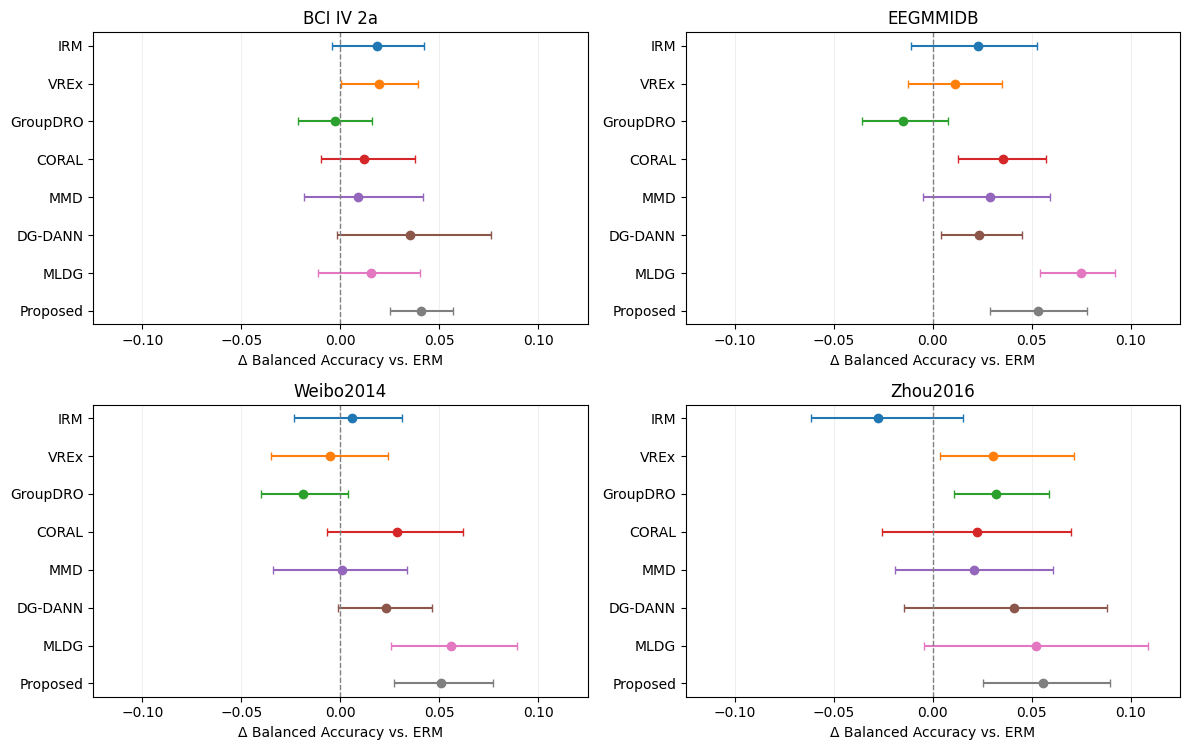

,Dataset,Method,Mean Delta BA,CI Lower,CI Upper,Subjects
0,BCI IV 2a,IRM,0.018,-0.004,0.042,9
1,BCI IV 2a,VREx,0.019,0.000,0.039,9
2,BCI IV 2a,GroupDRO,-0.003,-0.022,0.016,9
3,BCI IV 2a,CORAL,0.012,-0.010,0.037,9
4,BCI IV 2a,MMD,0.009,-0.018,0.042,9
5,BCI IV 2a,DG-DANN,0.035,-0.002,0.076,9
6,BCI IV 2a,MLDG,0.015,-0.011,0.040,9
7,BCI IV 2a,Proposed,0.041,0.025,0.057,9
8,EEGMMIDB,IRM,0.023,-0.011,0.053,10
9,EEGMMIDB,VREx,0.011,-0.013,0.035,10


In [5]:
def plot_generalization_improvement(results, methods=None, datasets=None,
                                    baseline="ERM", n_boot=2000, seed=42):
    methods = [m for m in (methods or results["Method"].unique()) if m != baseline]
    datasets = list(datasets or results["Dataset"].unique())
    rng = np.random.default_rng(seed)

    fig, axes = plt.subplots(
        (len(datasets) + 1) // 2, 2,
        figsize=(12, 3.8 * ((len(datasets) + 1) // 2)),
        squeeze=False
    )

    rows = []
    for ax, dataset in zip(axes.flat, datasets):
        subset = results[results["Dataset"] == dataset]
        pivot = subset.pivot_table(
            index="Subject", columns="Method", values="Test BA", aggfunc="mean"
        )

        for i, method in enumerate(methods):
            if baseline not in pivot or method not in pivot:
                continue

            paired = pivot[[baseline, method]].dropna()
            if paired.empty:
                continue

            delta = (paired[method] - paired[baseline]).to_numpy()
            mean = delta.mean()

            if len(delta) > 1:
                boot = rng.choice(delta, (n_boot, len(delta)), replace=True).mean(axis=1)
                low, high = np.quantile(boot, [0.025, 0.975])
                ax.errorbar(mean, i, xerr=[[mean - low], [high - mean]],
                            fmt="o", capsize=3)
            else:
                low = high = np.nan
                ax.plot(mean, i, "o")

            rows.append({
                "Dataset": dataset, "Method": method,
                "Mean Delta BA": mean, "CI Lower": low,
                "CI Upper": high, "Subjects": len(delta)
            })

        ax.axvline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_yticks(range(len(methods)))
        ax.set_yticklabels(methods)
        ax.invert_yaxis()
        ax.set_title(dataset)
        ax.set_xlabel("Δ Balanced Accuracy vs. ERM")
        ax.grid(axis="x", alpha=0.2)

    for ax in list(axes.flat)[len(datasets):]:
        ax.set_visible(False)

    summary = pd.DataFrame(rows)

    if not summary.empty:
        bounds = summary[["Mean Delta BA", "CI Lower", "CI Upper"]].abs()
        limit = max(0.02, bounds.max().max() * 1.15)
        for ax in list(axes.flat)[:len(datasets)]:
            ax.set_xlim(-limit, limit)

    fig.tight_layout()
    return fig, summary


# Test with synthetic data
fig, improvement_summary = plot_generalization_improvement(df, METHODS, DATASETS)
plt.show()
display(improvement_summary.round(3))

# plot_generalization_gap

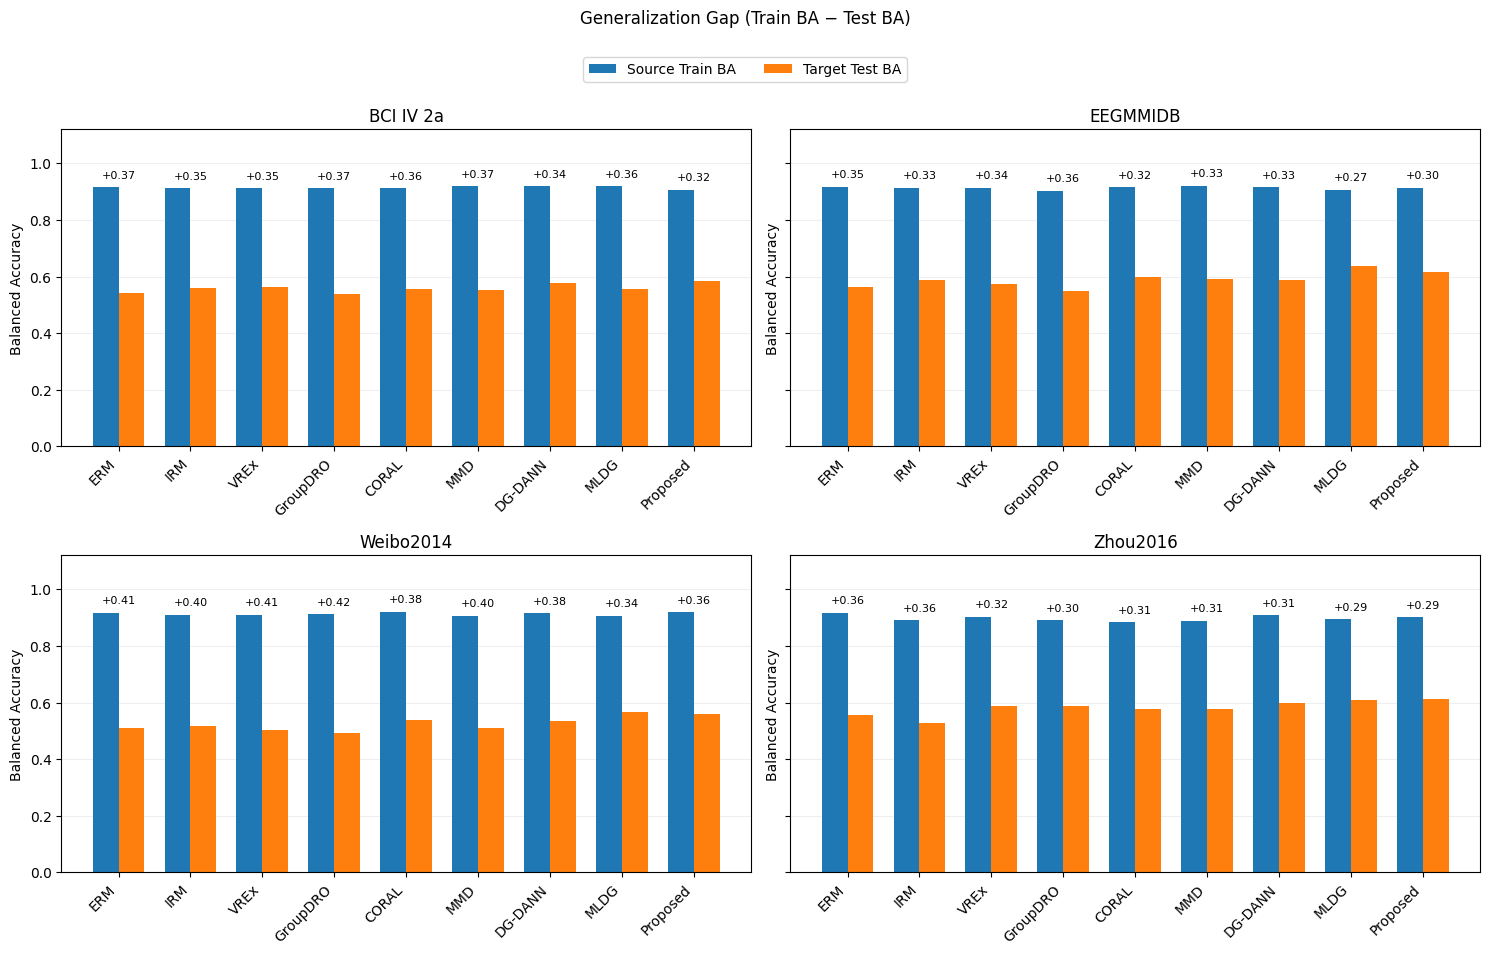

,Dataset,Method,Train_BA,Test_BA,Gap,Subjects
0,BCI IV 2a,CORAL,0.912,0.554,0.357,9
1,BCI IV 2a,DG-DANN,0.919,0.578,0.342,9
2,BCI IV 2a,ERM,0.915,0.542,0.373,9
3,BCI IV 2a,GroupDRO,0.912,0.540,0.373,9
4,BCI IV 2a,IRM,0.912,0.560,0.351,9
5,BCI IV 2a,MLDG,0.918,0.558,0.360,9
6,BCI IV 2a,MMD,0.919,0.551,0.368,9
7,BCI IV 2a,Proposed,0.907,0.583,0.324,9
8,BCI IV 2a,VREx,0.912,0.562,0.350,9
9,EEGMMIDB,CORAL,0.915,0.598,0.316,10


In [6]:
def plot_generalization_gap(results, methods=None, datasets=None):
    methods = list(methods) if methods is not None else results["Method"].unique().tolist()
    datasets = list(datasets) if datasets is not None else results["Dataset"].unique().tolist()

    # Aggregate within subjects before summarizing methods
    subject_results = (
        results.groupby(["Dataset", "Method", "Subject"], as_index=False)
        [["Train BA", "Test BA"]].mean()
        .dropna(subset=["Train BA", "Test BA"])
    )
    subject_results["Gap"] = subject_results["Train BA"] - subject_results["Test BA"]

    summary = (
        subject_results.groupby(["Dataset", "Method"], as_index=False)
        .agg(
            Train_BA=("Train BA", "mean"),
            Test_BA=("Test BA", "mean"),
            Gap=("Gap", "mean"),
            Subjects=("Subject", "nunique"),
        )
    )

    ncols = 2
    nrows = int(np.ceil(len(datasets) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(15, 4.5 * nrows),
        sharey=True, squeeze=False
    )

    x = np.arange(len(methods))
    width = 0.36

    for ax, dataset in zip(axes.flat, datasets):
        subset = summary[summary["Dataset"] == dataset].set_index("Method")
        subset = subset.reindex(methods)

        train = subset["Train_BA"].to_numpy()
        test = subset["Test_BA"].to_numpy()
        gap = subset["Gap"].to_numpy()

        ax.bar(x - width / 2, train, width, label="Source Train BA")
        ax.bar(x + width / 2, test, width, label="Target Test BA")

        for i, value in enumerate(gap):
            if np.isfinite(value):
                height = max(train[i], test[i])
                ax.text(i, height + 0.025, f"{value:+.2f}",
                        ha="center", va="bottom", fontsize=8)

        ax.set_title(dataset)
        ax.set_xticks(x)
        ax.set_xticklabels(methods, rotation=45, ha="right")
        ax.set_ylim(0, 1.12)
        ax.set_ylabel("Balanced Accuracy")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

    for ax in list(axes.flat)[len(datasets):]:
        ax.set_visible(False)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2,
               bbox_to_anchor=(0.5, 1.01))
    fig.suptitle("Generalization Gap (Train BA − Test BA)", y=1.055)
    fig.tight_layout()

    return fig, summary


# Test with synthetic data
fig, gap_summary = plot_generalization_gap(df, METHODS, DATASETS)
plt.show()
display(gap_summary.round(3))

# plot_subject_improvement

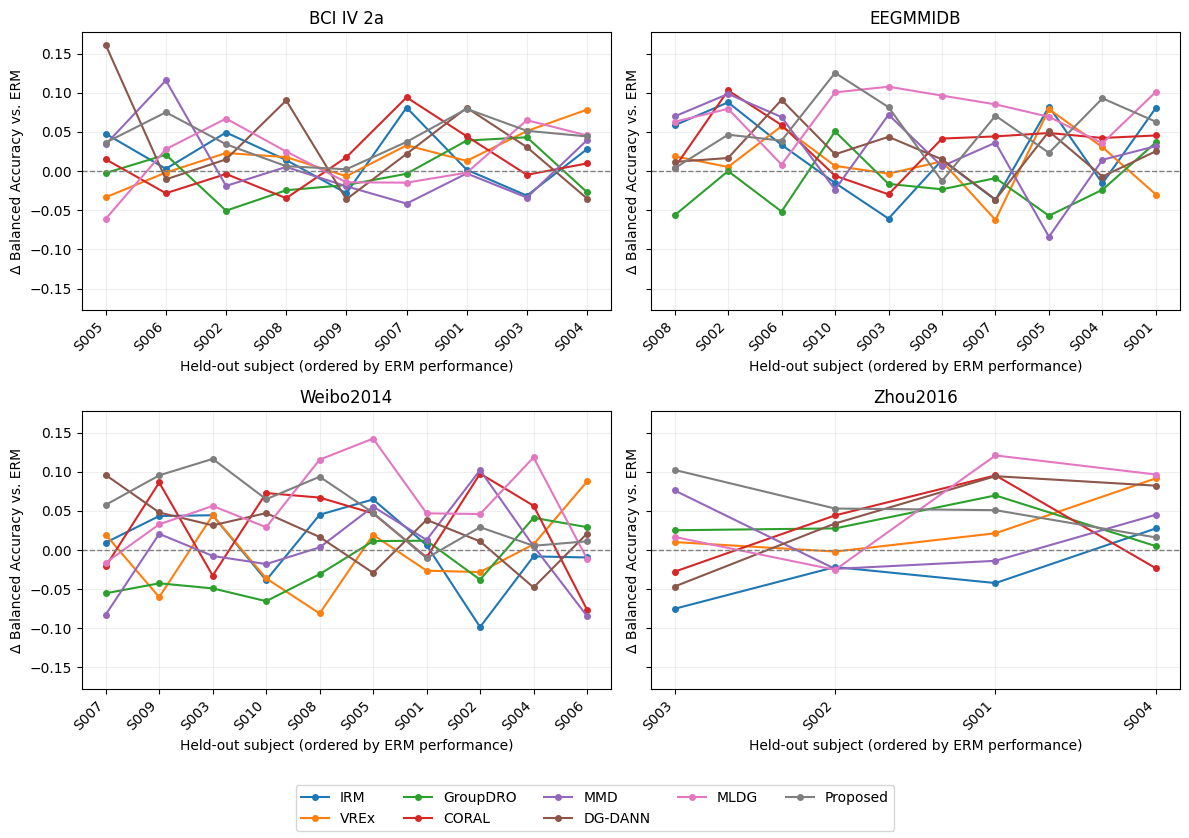

,Dataset,Subject,Method,ERM BA,Delta BA
0,BCI IV 2a,S005,IRM,0.375,0.048
1,BCI IV 2a,S006,IRM,0.440,0.003
2,BCI IV 2a,S002,IRM,0.466,0.049
3,BCI IV 2a,S008,IRM,0.538,0.014
4,BCI IV 2a,S009,IRM,0.568,-0.028
5,BCI IV 2a,S007,IRM,0.583,0.081
6,BCI IV 2a,S001,IRM,0.600,0.002
7,BCI IV 2a,S003,IRM,0.645,-0.031
8,BCI IV 2a,S004,IRM,0.664,0.028
9,BCI IV 2a,S005,VREx,0.375,-0.033


In [10]:
def plot_subject_improvement(results, methods=None, datasets=None, baseline="ERM"):
    methods = list(methods) if methods is not None else results["Method"].unique().tolist()
    methods = [m for m in methods if m != baseline]
    datasets = list(datasets) if datasets is not None else results["Dataset"].unique().tolist()

    rows = []
    ordered_data = {}

    for dataset in datasets:
        subset = results[results["Dataset"] == dataset]
        pivot = subset.pivot_table(
            index="Subject", columns="Method", values="Test BA", aggfunc="mean"
        )

        if baseline not in pivot:
            continue

        pivot = pivot.loc[pivot[baseline].notna()]
        pivot = pivot.loc[pivot[baseline].sort_values().index]

        delta = pivot.reindex(columns=methods).sub(pivot[baseline], axis=0)
        ordered_data[dataset] = delta

        for method in methods:
            for subject, value in delta[method].dropna().items():
                rows.append({
                    "Dataset": dataset,
                    "Subject": subject,
                    "Method": method,
                    "ERM BA": pivot.loc[subject, baseline],
                    "Delta BA": value,
                })

    if not ordered_data:
        raise ValueError("No paired subject-level results found.")

    ncols = 2
    nrows = int(np.ceil(len(ordered_data) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(12, 4.2 * nrows),
        sharey=True, squeeze=False
    )

    limit = max(
        0.05,
        max(np.nanmax(np.abs(delta.to_numpy(dtype=float)))
            for delta in ordered_data.values() if delta.notna().any().any())
    ) * 1.1

    for ax, (dataset, delta) in zip(axes.flat, ordered_data.items()):
        x = np.arange(len(delta.index))

        for method in methods:
            y = delta[method].to_numpy(dtype=float)
            ax.plot(x, y, marker="o", linewidth=1.5, markersize=4, label=method)

        subjects = delta.index.tolist()
        step = max(1, int(np.ceil(len(subjects) / 12)))
        ticks = np.arange(0, len(subjects), step)

        ax.axhline(0, color="gray", linestyle="--", linewidth=1)
        ax.set_xticks(ticks)
        ax.set_xticklabels([subjects[i] for i in ticks], rotation=45, ha="right")
        ax.set_title(dataset)
        ax.set_xlabel("Held-out subject (ordered by ERM performance)")
        ax.set_ylabel("Δ Balanced Accuracy vs. ERM")
        ax.set_ylim(-limit, limit)
        ax.grid(alpha=0.2)

    for ax in list(axes.flat)[len(ordered_data):]:
        ax.set_visible(False)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=min(5, len(methods)))
    fig.tight_layout(rect=[0, 0.08, 1, 1])

    return fig, pd.DataFrame(rows)


# Test with synthetic data
fig, subject_improvement = plot_subject_improvement(df, METHODS, DATASETS)
plt.show()
display(subject_improvement.head(10).round(3))

# plot_improvement_vs_difficulty

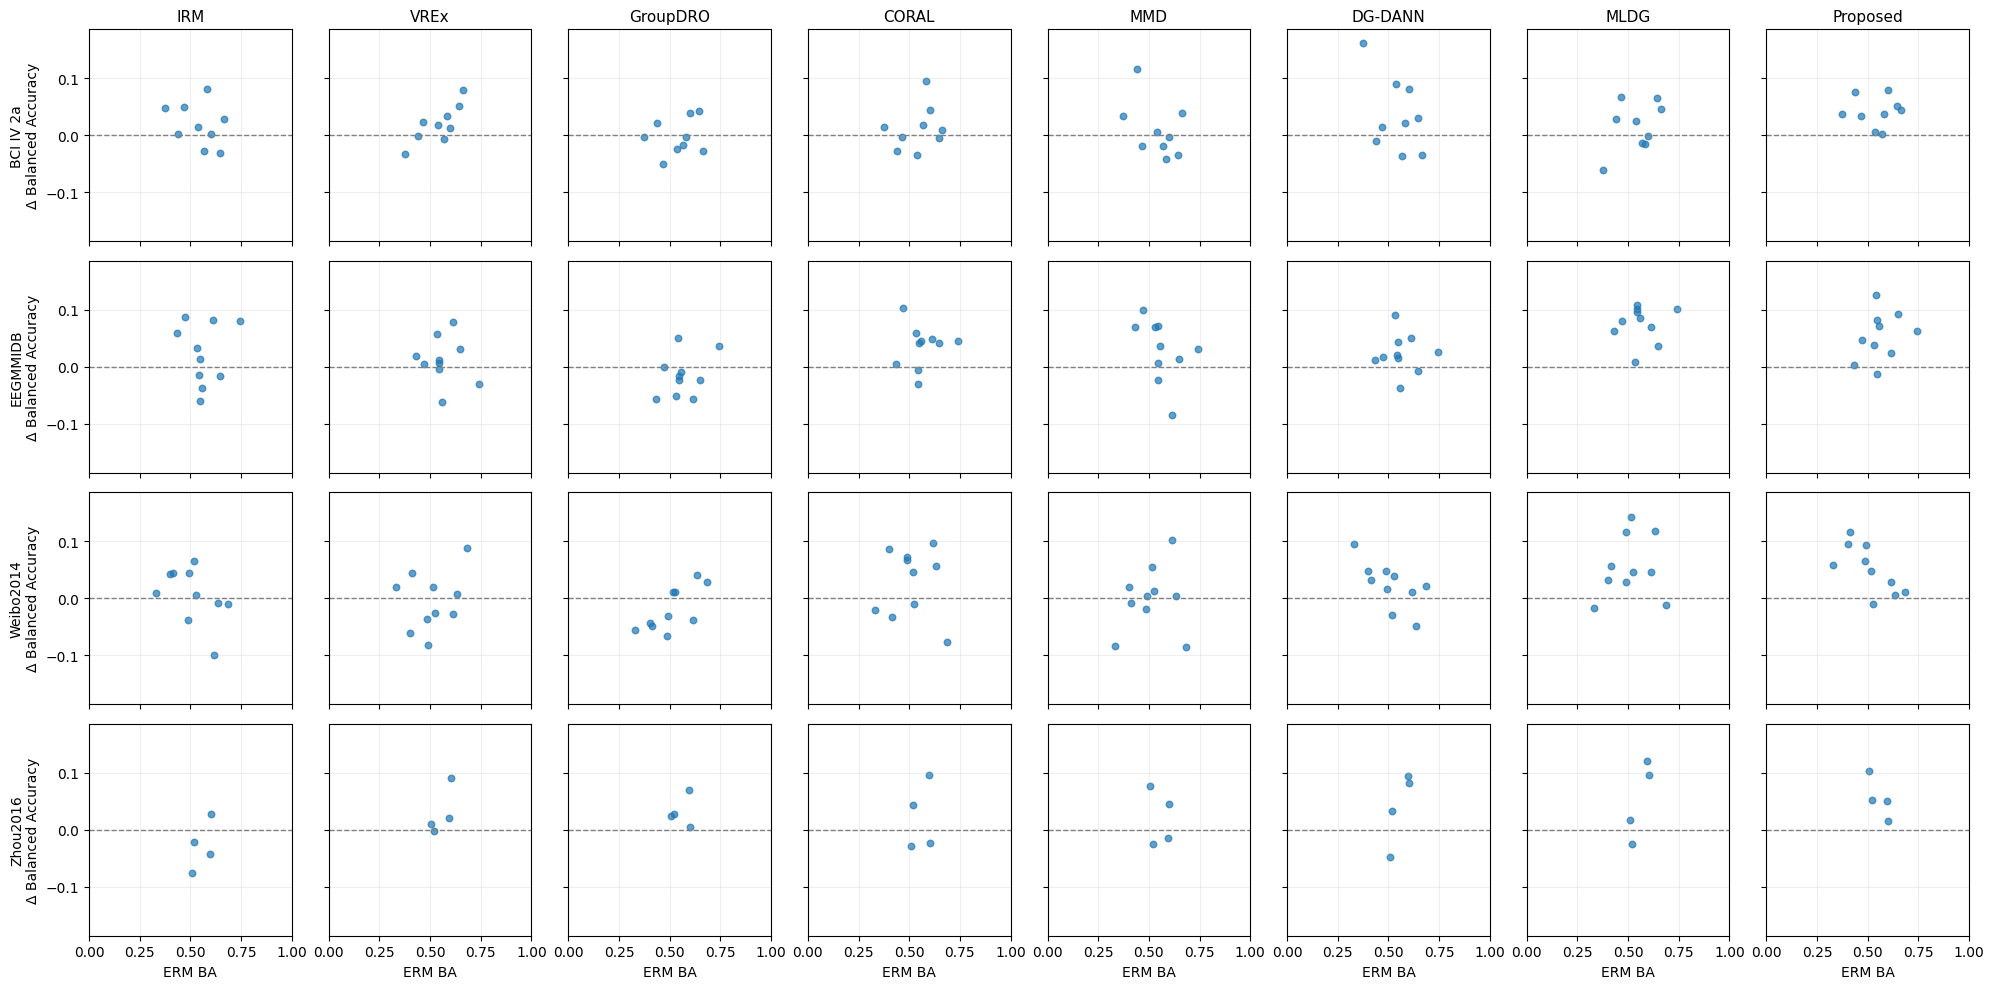

In [9]:

def plot_improvement_vs_difficulty(subject_results, methods=None, datasets=None):
    methods = list(methods) if methods is not None else subject_results["Method"].unique().tolist()
    datasets = list(datasets) if datasets is not None else subject_results["Dataset"].unique().tolist()

    nrows, ncols = len(datasets), len(methods)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(2.5 * ncols, 2.5 * nrows),
        sharex=True, sharey=True, squeeze=False
    )

    limit = max(0.05, subject_results["Delta BA"].abs().max() * 1.15)

    for i, dataset in enumerate(datasets):
        for j, method in enumerate(methods):
            ax = axes[i, j]
            data = subject_results[
                (subject_results["Dataset"] == dataset)
                & (subject_results["Method"] == method)
            ]

            ax.scatter(data["ERM BA"], data["Delta BA"], s=22, alpha=0.7)
            ax.axhline(0, color="gray", linestyle="--", linewidth=1)
            ax.set_xlim(0, 1)
            ax.set_ylim(-limit, limit)
            ax.grid(alpha=0.2)

            if i == 0:
                ax.set_title(method, fontsize=11)
            if j == 0:
                ax.set_ylabel(f"{dataset}\nΔ Balanced Accuracy")
            if i == nrows - 1:
                ax.set_xlabel("ERM BA")

    fig.tight_layout()
    return fig


# Test with synthetic data
fig = plot_improvement_vs_difficulty(
    subject_improvement,
    methods=[m for m in METHODS if m != "ERM"],
    datasets=list(DATASETS)
)
plt.show()
